In [48]:
import  numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings ('ignore')

In [49]:
df = sns.load_dataset('titanic')

In [50]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [51]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [52]:
df.shape

(891, 15)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [54]:
df.drop(["deck", "embark_town", "alive", "class", "who", "adult_male"], axis=1, inplace=True)



In [55]:
df['age'].fillna(df['age'].mean(), inplace = True)

In [56]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


In [57]:
df = df.dropna()

In [58]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  889 non-null    int64  
 1   pclass    889 non-null    int64  
 2   sex       889 non-null    object 
 3   age       889 non-null    float64
 4   sibsp     889 non-null    int64  
 5   parch     889 non-null    int64  
 6   fare      889 non-null    float64
 7   embarked  889 non-null    object 
 8   alone     889 non-null    bool   
dtypes: bool(1), float64(2), int64(4), object(2)
memory usage: 63.4+ KB


In [60]:
from sklearn.preprocessing import LabelEncoder

In [61]:
le = LabelEncoder()

In [62]:
df["sex"] = le.fit_transform(df["sex"])
df["embarked"] = le.fit_transform(df["embarked"])

In [63]:

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22.0,1,0,7.2500,2,False
1,1,1,0,38.0,1,0,71.2833,0,False
2,1,3,0,26.0,0,0,7.9250,2,True
3,1,1,0,35.0,1,0,53.1000,2,False
4,0,3,1,35.0,0,0,8.0500,2,True


In [64]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'alone'],
      dtype='object')

In [65]:
df = df.astype(int)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22,1,0,7,2,0
1,1,1,0,38,1,0,71,0,0
2,1,3,0,26,0,0,7,2,1
3,1,1,0,35,1,0,53,2,0
4,0,3,1,35,0,0,8,2,1


In [66]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22,1,0,7,2,0
1,1,1,0,38,1,0,71,0,0
2,1,3,0,26,0,0,7,2,1
3,1,1,0,35,1,0,53,2,0
4,0,3,1,35,0,0,8,2,1


In [67]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('survived', axis=1)
y = df['survived']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [68]:
from sklearn.linear_model import LogisticRegression

# Train model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

In [69]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8033707865168539

Confusion Matrix:
 [[90 19]
 [16 53]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.83      0.84       109
           1       0.74      0.77      0.75        69

    accuracy                           0.80       178
   macro avg       0.79      0.80      0.79       178
weighted avg       0.81      0.80      0.80       178



In [70]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [71]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [72]:
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled ,y_train)

KNeighborsClassifier()

In [73]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [74]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))

Accuracy: 0.7752808988764045

Confusion Matrix:
 [[89 20]
 [20 49]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.82      0.82       109
           1       0.71      0.71      0.71        69

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.78      0.78      0.78       178



In [75]:
from sklearn.naive_bayes import GaussianNB


In [76]:
NB_model = GaussianNB()
NB_model.fit(X_train_scaled , y_train)

GaussianNB()

In [77]:
y_pred_NB = NB_model.predict(X_test_scaled)

In [78]:
print("Accuracy:", accuracy_score(y_test, y_pred_NB))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_NB))
print("\nClassification Report:\n", classification_report(y_test, y_pred_NB))

Accuracy: 0.7528089887640449

Confusion Matrix:
 [[89 20]
 [24 45]]

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.82      0.80       109
           1       0.69      0.65      0.67        69

    accuracy                           0.75       178
   macro avg       0.74      0.73      0.74       178
weighted avg       0.75      0.75      0.75       178



In [79]:
from sklearn.tree import DecisionTreeClassifier

In [80]:
DT_model = DecisionTreeClassifier(random_state=42)
DT_model.fit(X_train_scaled , y_train)

DecisionTreeClassifier(random_state=42)

In [81]:
y_pred_DT = DT_model.predict(X_test_scaled)

In [82]:
print("Accuracy:", accuracy_score(y_test, y_pred_DT))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_DT))
print("\nClassification Report:\n", classification_report(y_test, y_pred_DT))

Accuracy: 0.7696629213483146

Confusion Matrix:
 [[88 21]
 [20 49]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81       109
           1       0.70      0.71      0.71        69

    accuracy                           0.77       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.77      0.77       178



In [83]:
from sklearn.svm import SVC

In [84]:
model_svm = SVC()
model_svm.fit(X_train_scaled , y_train)

SVC()

In [85]:
y_pred_svm = model_svm.predict(X_test_scaled)

In [86]:
y_pred_svm

array([0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1])

In [87]:
print("Accuracy:", accuracy_score(y_test, y_pred_DT))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_DT))
print("\nClassification Report:\n", classification_report(y_test, y_pred_DT))

Accuracy: 0.7696629213483146

Confusion Matrix:
 [[88 21]
 [20 49]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81       109
           1       0.70      0.71      0.71        69

    accuracy                           0.77       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.77      0.77       178



,Model,Accuracy
0,Support Vector Machine,0.825843
1,Logistic Regression,0.803371
2,K-Nearest Neighbors,0.775281
3,Decision Tree,0.769663
4,Naive Bayes,0.752809


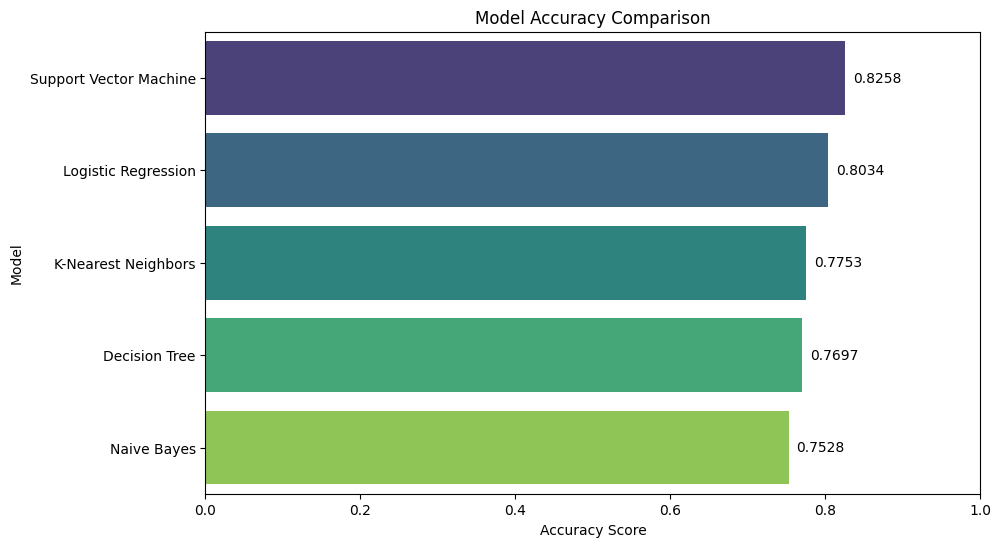

In [88]:
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate accuracies for all models
acc_log_reg = accuracy_score(y_test, y_pred)
acc_knn = accuracy_score(y_test, y_pred_knn)
acc_nb = accuracy_score(y_test, y_pred_NB)
acc_dt = accuracy_score(y_test, y_pred_DT)
acc_svm = accuracy_score(y_test, y_pred_svm)

# Create a comparison DataFrame
accuracy_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'K-Nearest Neighbors', 'Naive Bayes', 'Decision Tree', 'Support Vector Machine'],
    'Accuracy': [acc_log_reg, acc_knn, acc_nb, acc_dt, acc_svm]
}).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

# Display the DataFrame
display(accuracy_df)

# Plot the comparison
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Model', data=accuracy_df, palette='viridis')
plt.title('Model Accuracy Comparison')
plt.xlabel('Accuracy Score')
plt.ylabel('Model')
plt.xlim(0, 1.0)

# Annotate the actual accuracy values on the bars
for index, value in enumerate(accuracy_df['Accuracy']):
    plt.text(value + 0.01, index, f'{value:.4f}', va='center')

plt.show()

,Model,Mean CV Accuracy,CV Accuracy Std
0,Support Vector Machine,0.824528,0.016842
1,K-Nearest Neighbors,0.803115,0.034262
2,Logistic Regression,0.796412,0.023242
3,Decision Tree,0.788496,0.042158
4,Naive Bayes,0.776124,0.025404


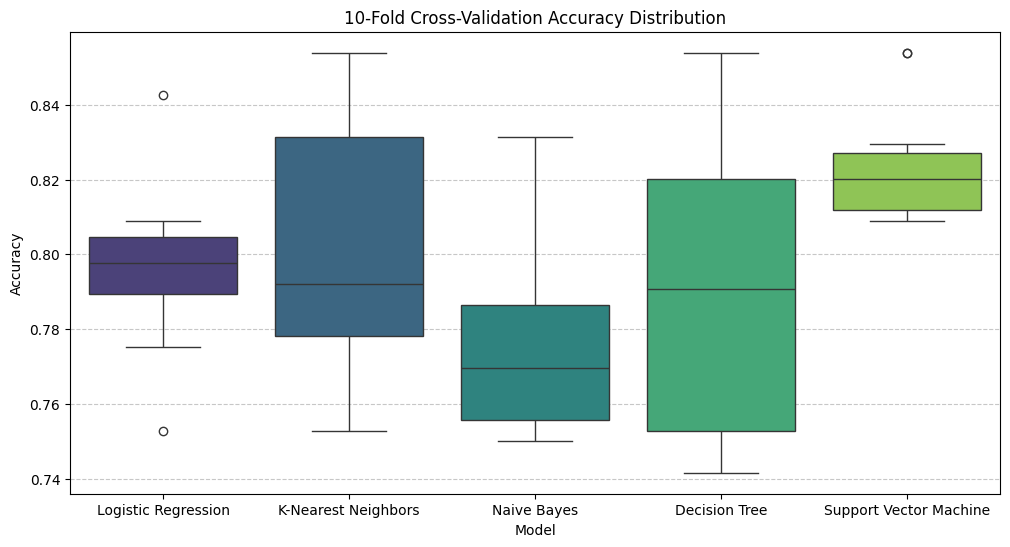

In [89]:
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Combine train and test scaled features for overall CV
X_scaled = np.vstack((X_train_scaled, X_test_scaled))
y_combined = pd.concat([y_train, y_test], axis=0)

# Define models
models = {
    'Logistic Regression': model,
    'K-Nearest Neighbors': knn_model,
    'Naive Bayes': NB_model,
    'Decision Tree': DT_model,
    'Support Vector Machine': model_svm
}

# Calculate Cross-Validation Scores
cv_results = {}
for name, clf in models.items():
    scores = cross_val_score(clf, X_scaled, y_combined, cv=10, scoring='accuracy')
    cv_results[name] = scores

# Create DataFrame for results visualization
cv_df = pd.DataFrame(cv_results)

# Summary stats
summary_df = pd.DataFrame({
    'Model': cv_df.columns,
    'Mean CV Accuracy': cv_df.mean(),
    'CV Accuracy Std': cv_df.std()
}).sort_values(by='Mean CV Accuracy', ascending=False).reset_index(drop=True)

display(summary_df)

# Plot CV accuracy distributions
plt.figure(figsize=(12, 6))
sns.boxplot(data=cv_df, palette='viridis')
plt.title('10-Fold Cross-Validation Accuracy Distribution')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [47]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Define the parameter grid to search
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear', 'poly']
}

# Initialize the SVM model
base_svm = SVC(random_state=42)

# Setup GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=base_svm,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Fit the grid search to the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Print the best parameters and corresponding accuracy
print("Best Parameters found:", grid_search.best_params_)
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

# Evaluate the optimized model on the test set
best_svm_model = grid_search.best_estimator_
test_accuracy = best_svm_model.score(X_test_scaled, y_test)
print(f"Test Set Accuracy with Best Model: {test_accuracy:.4f}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters found: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Score: 0.8284
Test Set Accuracy with Best Model: 0.8258
